# Session 14 Assignment — Train a dense model, then grow it into a Mixture-of-Experts

**Task:** train a dense ("linear" feed-forward) model, convert it into an MoE, and show that the MoE keeps training and keeps reducing the loss.

**What this notebook does**

| Phase | What happens | Lesson link |
|---|---|---|
| 1 | Train a small dense GPT (6 layers, d=384, SwiGLU FFN width 1,536) on TinyStories, byte-level | §3 the FFN we will replace |
| 2 | **Upcycle** the trained FFN of every layer into experts, three ways: **copy** (sparse upcycling), **drop** (drop-upcycling, r = 0.5), **partition** (fine-grained, Qwen-style, compute-matched) | §15 growing an MoE |
| 3 | Continue training all MoE variants **and** a dense control on identical data for the same number of steps | "must show they continue to train and reduce loss" |
| 4 | Inspect load balance (MaxVio, dead experts), expert specialization by token type, and samples | §9, §10, §13, §14 |

**MoE recipe used (straight from the lesson's "V5 decisions", §20)**
- router computed in **fp32**, initialised small (§7)
- softmax scores → top-k → renormalise; optional **routed scaling factor** for fine-grained experts (§7)
- **aux-loss-free balancing**: per-expert bias used only for *choosing*, updated by `b += γ·sign(mean_load − load)` (§13), plus a tiny aux loss 1e-4 and router z-loss 1e-3 (§12)
- load counted over the **whole batch**, not per sequence (§14)
- **dropless** routing (§11): every token is processed by all of its k experts
- **probabilistic (Gumbel top-k) selection for the first steps** after growth, so cloned experts all receive gradient before the router settles (§15, Lightning LM "collapse along clone families")

Runtime: ~55 min on a free **T4** (measured), roughly 15–20 min on an A100/L4. Set `QUICK = True` for a 3-minute smoke test.

In [1]:
# !pip -q install datasets   # already present on Colab; uncomment if needed
import os, math, time, copy, random
from dataclasses import dataclass, replace
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

QUICK = False         # True -> tiny run to check everything works end to end
SEED  = 1337
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
if device == 'cuda':
    major, _ = torch.cuda.get_device_capability()
    amp_dtype = torch.bfloat16 if major >= 8 else torch.float16   # T4 (sm75) -> fp16 + GradScaler
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    print('GPU:', torch.cuda.get_device_name(0), '| amp dtype:', amp_dtype)
else:
    amp_dtype = torch.float32
    print('No GPU found - this will be slow. Runtime > Change runtime type > GPU.')
use_amp = device == 'cuda'
print('torch', torch.__version__)

GPU: Tesla T4 | amp dtype: torch.float16
torch 2.11.0+cu128


## 1. Data — TinyStories, byte-level (vocab = 256)

Byte-level tokens keep the model small and make the expert-specialization analysis easy to read (spaces vs punctuation vs letters — exactly the "kind of token" specialization described in §9).
TinyStories is large enough (we take ~100 MB) that neither phase overfits, so a falling validation loss means real learning.

In [2]:
DATA_DIR = '/content/data' if os.path.isdir('/content') else './data'
os.makedirs(DATA_DIR, exist_ok=True)
TRAIN_BYTES = 5_000_000 if QUICK else 100_000_000
VAL_BYTES   =   500_000 if QUICK else   2_000_000

def load_tinystories(split, n_bytes):
    from datasets import load_dataset
    ds = load_dataset('roneneldan/TinyStories', split=split, streaming=True)
    chunks, total = [], 0
    for ex in ds:
        b = (ex['text'].strip() + '\n\n').encode('utf-8')
        chunks.append(b); total += len(b)
        if total >= n_bytes:
            break
    return np.frombuffer(b''.join(chunks), dtype=np.uint8).copy()

def load_shakespeare():
    import urllib.request
    url = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
    arr = np.frombuffer(urllib.request.urlopen(url).read(), dtype=np.uint8).copy()
    n = int(0.95 * len(arr))
    return arr[:n], arr[n:]

tr_path = f'{DATA_DIR}/train_{TRAIN_BYTES}.npy'; va_path = f'{DATA_DIR}/val_{VAL_BYTES}.npy'
if os.path.exists(tr_path) and os.path.exists(va_path):
    train_np, val_np = np.load(tr_path), np.load(va_path)
    DATASET = 'TinyStories (cached)'
else:
    try:
        t0 = time.time()
        train_np = load_tinystories('train', TRAIN_BYTES)
        val_np   = load_tinystories('validation', VAL_BYTES)
        np.save(tr_path, train_np); np.save(va_path, val_np)
        DATASET = 'TinyStories'
        print(f'downloaded in {time.time()-t0:.0f}s')
    except Exception as e:
        print('TinyStories failed (', repr(e)[:120], ') -> falling back to tiny-shakespeare')
        train_np, val_np = load_shakespeare()
        DATASET = 'tiny-shakespeare'

train_data = torch.from_numpy(train_np)
val_data   = torch.from_numpy(val_np)
print(f'{DATASET}: train {len(train_data)/1e6:.1f}M bytes, val {len(val_data)/1e6:.2f}M bytes')
print(bytes(train_np[:300]).decode('utf-8', errors='replace'))

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

downloaded in 26s
TinyStories: train 100.0M bytes, val 2.00M bytes
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and 


In [3]:
BLOCK = 128 if QUICK else 256
BATCH = 32  if QUICK else 64

def get_batch(data, B=None, T=None, gen=None):
    B = B or BATCH; T = T or BLOCK
    ix = torch.randint(len(data) - T - 1, (B,), generator=gen)
    x = torch.stack([data[i:i+T] for i in ix]).long()
    y = torch.stack([data[i+1:i+T+1] for i in ix]).long()
    if device == 'cuda':
        return x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
    return x, y

# A FIXED set of validation batches, so every model / arm is scored on exactly the same bytes
EVAL_ITERS = 5 if QUICK else 20
_g = torch.Generator().manual_seed(123)
VAL_BATCHES = [get_batch(val_data, gen=_g) for _ in range(EVAL_ITERS)]

## 2. Model — a small GPT whose FFN can be dense *or* a Mixture-of-Experts

* `SwiGLU` is the dense feed-forward network: gate and up matrices widen 384 → hidden, down brings it back (§2).
* `MoELayer` keeps attention untouched and replaces the FFN with a router + experts, `y = Σ_{i∈TopK} g_i · E_i(x)` (§3).
* The router runs in fp32; the bias is used **only for choosing** experts, the weights `g_i` come from the raw softmax scores (§13).
* `explore=True` switches choosing to Gumbel-top-k, i.e. sampling k experts without replacement from the router's distribution (the "probabilistic selection" window of §15).

In [4]:
@dataclass
class GPTConfig:
    vocab_size: int = 256
    block_size: int = 256
    n_layer: int = 6
    n_head: int = 6
    n_embd: int = 384
    ffn_hidden: int = 1536       # dense SwiGLU width (4x d)
    # --- MoE ---
    moe: bool = False
    n_experts: int = 8
    top_k: int = 2
    expert_hidden: int = 1536    # width of ONE expert
    routed_scale: float = 1.0    # routed scaling factor (§7)

class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.eps = eps; self.weight = nn.Parameter(torch.ones(d))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

class Attention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.n_head = cfg.n_head
        self.qkv  = nn.Linear(cfg.n_embd, 3 * cfg.n_embd, bias=False)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=False)
    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = (t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.proj(y.transpose(1, 2).contiguous().view(B, T, C))

class SwiGLU(nn.Module):
    '''The dense FFN, and also the shape of every expert.'''
    def __init__(self, d, h):
        super().__init__()
        self.w_gate = nn.Linear(d, h, bias=False)
        self.w_up   = nn.Linear(d, h, bias=False)
        self.w_down = nn.Linear(h, d, bias=False)
    def forward(self, x):
        return self.w_down(F.silu(self.w_gate(x)) * self.w_up(x))

class MoELayer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.E, self.k, self.scale = cfg.n_experts, cfg.top_k, cfg.routed_scale
        self.router  = nn.Linear(cfg.n_embd, cfg.n_experts, bias=False)
        self.experts = nn.ModuleList([SwiGLU(cfg.n_embd, cfg.expert_hidden) for _ in range(cfg.n_experts)])
        self.register_buffer('sel_bias',    torch.zeros(cfg.n_experts))   # aux-loss-free balancing bias
        self.register_buffer('step_counts', torch.zeros(cfg.n_experts))   # load since last bias update
        self.explore = False       # Gumbel-top-k (probabilistic) selection
        self.record  = False       # keep the chosen experts for analysis
        self.aux_loss = self.z_loss = None
        self.last_counts = None; self.last_topi = None

    def forward(self, x):
        B, T, C = x.shape
        xf = x.reshape(-1, C)
        N = xf.shape[0]
        # ---- router in fp32 (Switch Transformer stability trick) ----
        with torch.autocast(device_type=xf.device.type, enabled=False):
            logits = self.router(xf.float())                       # (N, E)
        probs = logits.softmax(dim=-1)
        # ---- choose (bias only affects the choice) ----
        if self.training and self.explore:
            u = torch.rand_like(probs).clamp_(1e-9, 1 - 1e-9)
            choice = torch.log(probs + 1e-9) - torch.log(-torch.log(u)) + self.sel_bias
        else:
            choice = probs + self.sel_bias
        top_i = choice.topk(self.k, dim=-1).indices                  # (N, k)
        top_w = probs.gather(-1, top_i)
        top_w = top_w / top_w.sum(-1, keepdim=True) * self.scale     # weights from the raw scores

        # ---- dropless dispatch: group assignments by expert ----
        flat_e = top_i.reshape(-1)                                   # (N*k,)
        flat_w = top_w.reshape(-1)
        flat_t = torch.arange(N, device=x.device).repeat_interleave(self.k)
        order  = flat_e.argsort()
        counts = torch.bincount(flat_e, minlength=self.E)
        sorted_t, sorted_w = flat_t[order], flat_w[order]
        out = torch.zeros(N, C, device=x.device, dtype=torch.float32)
        start = 0
        for e, c in enumerate(counts.tolist()):
            if c == 0:
                continue
            t = sorted_t[start:start + c]
            y = self.experts[e](xf[t])
            out.index_add_(0, t, y.float() * sorted_w[start:start + c, None])
            start += c

        # ---- balancing signals ----
        if self.training:
            f = counts.float() / (N * self.k)                        # share of assignments (whole batch, §14)
            P = probs.mean(0)                                        # mean router prob
            self.aux_loss = self.E * (f * P).sum()                   # = 1.0 when perfectly even
            self.z_loss   = torch.logsumexp(logits, dim=-1).pow(2).mean()
            self.step_counts += counts.detach().float()
        self.last_counts = counts.detach()
        if self.record:
            self.last_topi = top_i.detach().view(B, T, self.k)
        return out.view(B, T, C).to(x.dtype)

    @torch.no_grad()
    def update_bias(self, gamma):
        load = self.step_counts
        if gamma > 0 and load.sum() > 0:
            self.sel_bias += gamma * torch.sign(load.mean() - load)
        self.step_counts.zero_()

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.attn = RMSNorm(cfg.n_embd), Attention(cfg)
        self.ln2 = RMSNorm(cfg.n_embd)
        self.ffn = MoELayer(cfg) if cfg.moe else SwiGLU(cfg.n_embd, cfg.ffn_hidden)
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.ffn(self.ln2(x))

class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.pos_emb = nn.Embedding(cfg.block_size, cfg.n_embd)
        self.blocks  = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.ln_f    = RMSNorm(cfg.n_embd)
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight                  # weight tying
        self.apply(self._init)
        for n, p in self.named_parameters():                       # scaled init of residual outputs
            if n.endswith('proj.weight') or n.endswith('w_down.weight'):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * cfg.n_layer))
    def _init(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)
    def moe_layers(self):
        return [b.ffn for b in self.blocks if isinstance(b.ffn, MoELayer)]
    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        for b in self.blocks:
            x = b(x)
        logits = self.lm_head(self.ln_f(x))
        loss = None if targets is None else F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

def param_counts(model):
    total = sum(p.numel() for p in model.parameters())          # tied weights counted once
    moes = model.moe_layers()
    if not moes:
        return total, total
    per_expert = sum(p.numel() for p in moes[0].experts[0].parameters())
    active = total - len(moes) * (moes[0].E - moes[0].k) * per_expert
    return total, active

def fmt(n): return f'{n/1e6:.2f}M'

## 3. Shared training loop

One loop for every model. For MoE models it adds the tiny aux loss and the z-loss, updates each layer's selection bias after every optimizer step, and records load statistics (MaxVio and dead experts, §10).
All arms of the continuation phase use the **same data order** (a dedicated generator) so the curves are directly comparable.

In [5]:
@torch.no_grad()
def evaluate(model):
    was_training = model.training
    model.eval()
    losses = []
    for x, y in VAL_BATCHES:
        with torch.autocast(device_type=device, dtype=amp_dtype, enabled=use_amp):
            _, loss = model(x, y)
        losses.append(loss.item())
    model.train(was_training)
    return float(np.mean(losses))

def make_optimizer(model, lr, wd=0.1):
    decay   = [p for p in model.parameters() if p.dim() >= 2]
    nodecay = [p for p in model.parameters() if p.dim() < 2]
    kw = dict(fused=True) if device == 'cuda' else {}
    return torch.optim.AdamW([{'params': decay, 'weight_decay': wd},
                              {'params': nodecay, 'weight_decay': 0.0}], lr=lr, betas=(0.9, 0.95), **kw)

def lr_at(it, steps, lr_max, warmup, decay_frac=0.25, lr_min_ratio=0.1):
    '''warmup -> constant -> linear decay in the last `decay_frac` of steps (WSD schedule)'''
    if it < warmup:
        return lr_max * (it + 1) / warmup
    decay_start = int(steps * (1 - decay_frac))
    if it < decay_start:
        return lr_max
    frac = (it - decay_start) / max(1, steps - decay_start)
    return lr_max * (1 - frac * (1 - lr_min_ratio))

def train(model, steps, lr_max, warmup, *, step_offset=0, eval_every=100, data_seed=0,
          decay_frac=0.25, explore_steps=0, bias_gamma=1e-3, aux_coef=1e-4, z_coef=1e-3,
          window=50, tag=''):
    model.train()
    opt = make_optimizer(model, lr_max)
    scaler = torch.amp.GradScaler('cuda', enabled=(use_amp and amp_dtype == torch.float16))
    gen = torch.Generator().manual_seed(data_seed)
    moes = model.moe_layers()
    L = len(moes)
    E = moes[0].E if moes else 0
    H = dict(val_step=[], val=[], tr_step=[], tr=[], mv_step=[], maxvio=[], dead=[], load=None, sec_per_step=None)
    win = torch.zeros(L, E, device=device) if moes else None
    win_n = 0
    ema = None
    t0 = time.time(); timed_steps = 0
    for it in range(steps + 1):
        if it % eval_every == 0 or it == steps:
            v = evaluate(model)
            H['val_step'].append(step_offset + it); H['val'].append(v)
            extra = ''
            if moes and H['maxvio']:
                extra = f" | MaxVio {H['maxvio'][-1]:.2f} | dead {H['dead'][-1]}/{L*E}"
            print(f"[{tag}] step {step_offset+it:5d} | val {v:.4f} | train(ema) {ema if ema is not None else float('nan'):.4f}{extra}")
        if it == steps:
            break
        lr = lr_at(it, steps, lr_max, warmup, decay_frac)
        for g in opt.param_groups:
            g['lr'] = lr
        for m in moes:
            m.explore = it < explore_steps
        x, y = get_batch(train_data, gen=gen)
        with torch.autocast(device_type=device, dtype=amp_dtype, enabled=use_amp):
            _, loss = model(x, y)
            total = loss
            if moes:
                total = total + aux_coef * sum(m.aux_loss for m in moes) + z_coef * sum(m.z_loss for m in moes)
        scaler.scale(total).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        opt.zero_grad(set_to_none=True)

        if moes:
            win += torch.stack([m.last_counts.float() for m in moes])
            win_n += 1
            for m in moes:
                m.update_bias(bias_gamma)
            if win_n == window:
                mean = win.mean(1, keepdim=True)
                maxvio = ((win.max(1, keepdim=True).values - mean) / mean).mean().item()   # avg over layers
                H['mv_step'].append(step_offset + it + 1); H['maxvio'].append(maxvio)
                H['dead'].append(int((win == 0).sum().item()))
                H['load'] = (win / win.sum(1, keepdim=True)).cpu().numpy()
                win.zero_(); win_n = 0

        li = loss.item()
        ema = li if ema is None else 0.98 * ema + 0.02 * li
        if it % 10 == 0:
            H['tr_step'].append(step_offset + it); H['tr'].append(ema)
        timed_steps += 1
    if device == 'cuda':
        torch.cuda.synchronize()
    H['sec_per_step'] = (time.time() - t0) / max(1, timed_steps)
    for m in moes:
        m.explore = False
    return H

## 4. Phase 1 — train the dense model

Warm-up then constant LR (a WSD schedule without its decay), so the checkpoint we grow from is a model that is **still learning**. That makes the comparison with the dense control honest: the control keeps training from exactly the same point.

In [6]:
if QUICK:
    cfg = GPTConfig(block_size=BLOCK, n_layer=2, n_head=4, n_embd=128, ffn_hidden=512, expert_hidden=512)
    DENSE_STEPS, CONT_STEPS = 200, 150
else:
    cfg = GPTConfig(block_size=BLOCK)
    DENSE_STEPS, CONT_STEPS = 3000, 2000
LR = 1e-3

torch.manual_seed(SEED)
dense = GPT(cfg).to(device)
print('dense params:', fmt(param_counts(dense)[0]))

hist_dense = train(dense, DENSE_STEPS, LR, warmup=200, eval_every=250 if not QUICK else 50,
                   data_seed=1, decay_frac=0.0, tag='dense')
print(f"dense: {hist_dense['sec_per_step']*1000:.0f} ms/step")
torch.save(dense.state_dict(), f'{DATA_DIR}/dense_ckpt.pt')
DENSE_CKPT_VAL = hist_dense['val'][-1]

dense params: 14.36M
[dense] step     0 | val 5.4892 | train(ema) nan
[dense] step   250 | val 1.4851 | train(ema) 1.7711
[dense] step   500 | val 0.9881 | train(ema) 1.0437
[dense] step   750 | val 0.8721 | train(ema) 0.8957
[dense] step  1000 | val 0.8126 | train(ema) 0.8296
[dense] step  1250 | val 0.7730 | train(ema) 0.7832
[dense] step  1500 | val 0.7460 | train(ema) 0.7554
[dense] step  1750 | val 0.7258 | train(ema) 0.7371
[dense] step  2000 | val 0.7122 | train(ema) 0.7191
[dense] step  2250 | val 0.6984 | train(ema) 0.7077
[dense] step  2500 | val 0.6899 | train(ema) 0.6956
[dense] step  2750 | val 0.6827 | train(ema) 0.6855
[dense] step  3000 | val 0.6769 | train(ema) 0.6793
dense: 159 ms/step


## 5. Upcycling: dense FFN → experts (§15)

For every layer, each expert gets its first weights from the trained dense FFN:

| method | expert shape | how an expert starts | active FFN compute vs dense |
|---|---|---|---|
| **copy** (sparse upcycling, Komatsuzaki et al. 2022) | 8 × 1,536, top-2 | an exact copy of the dense FFN | 2× |
| **drop** (drop-upcycling, r = 0.5) | 8 × 1,536, top-2 | a copy with a *different* random half of its hidden neurons redrawn from N(mean, std) of the original matrix | 2× |
| **partition** (fine-grained, Qwen1.5-MoE style) | 32 × 192, top-8, routed scale 8 | 4 shuffled copies of the 1,536 neurons cut into 192-wide slices | **1× (compute-matched, 8 × 192 = 1,536)** |

The partition arm mirrors the lesson's reference model, where 8 × 768 = 6,144 = one dense FFN.

Every expert-less weight (embeddings, attention, norms) is copied unchanged. The router is new and initialised small.

**Why copy is function-preserving:** all experts equal the dense FFN, and the top-k weights add up to 1, so `Σ g_i·FFN(x) = FFN(x)`. The MoE starts with *exactly* the dense model's loss — we check this below.

In [7]:
@torch.no_grad()
def upcycle(dense, method, n_experts, top_k, expert_hidden=None, routed_scale=1.0,
            drop_ratio=0.0, router_std=0.01, seed=0):
    H = dense.cfg.ffn_hidden
    expert_hidden = expert_hidden or H
    mcfg = replace(dense.cfg, moe=True, n_experts=n_experts, top_k=top_k,
                   expert_hidden=expert_hidden, routed_scale=routed_scale)
    moe = GPT(mcfg).to(device)
    sd = {k: v for k, v in dense.state_dict().items() if '.ffn.' not in k}
    missing, unexpected = moe.load_state_dict(sd, strict=False)
    assert not unexpected and all('.ffn.' in k for k in missing), (missing, unexpected)

    g = torch.Generator().manual_seed(seed)
    for db, mb in zip(dense.blocks, moe.blocks):
        Wg, Wu, Wd = db.ffn.w_gate.weight, db.ffn.w_up.weight, db.ffn.w_down.weight   # (H,d) (H,d) (d,H)
        # 1) which dense neurons each expert starts from
        if method in ('copy', 'drop'):
            assert expert_hidden == H
            slices = [torch.arange(H) for _ in range(n_experts)]
        elif method == 'partition':
            n_copies = n_experts * expert_hidden // H
            assert n_copies * H == n_experts * expert_hidden, 'experts must tile whole copies of the FFN'
            slices = []
            for _ in range(n_copies):
                slices += list(torch.randperm(H, generator=g).split(expert_hidden))
        else:
            raise ValueError(method)
        # 2) copy the slices, then (optionally) redraw a fraction of each expert's neurons
        for ex, idx in zip(mb.ffn.experts, slices):
            idx = idx.to(Wg.device)
            wg, wu, wd = Wg[idx].clone(), Wu[idx].clone(), Wd[:, idx].clone()
            if drop_ratio > 0:
                r = torch.randperm(expert_hidden, generator=g)[:int(drop_ratio * expert_hidden)].to(Wg.device)
                def redraw(shape, ref):
                    return (torch.randn(shape, generator=g) * ref.std().item() + ref.mean().item()).to(ref.device, ref.dtype)
                wg[r]    = redraw((len(r), wg.shape[1]), Wg)
                wu[r]    = redraw((len(r), wu.shape[1]), Wu)
                wd[:, r] = redraw((wd.shape[0], len(r)), Wd)
            ex.w_gate.weight.copy_(wg); ex.w_up.weight.copy_(wu); ex.w_down.weight.copy_(wd)
        # 3) fresh, small router; zero bias
        mb.ffn.router.weight.copy_(torch.randn(mb.ffn.router.weight.shape, generator=g) * router_std)
        mb.ffn.sel_bias.zero_(); mb.ffn.step_counts.zero_()
    return moe

ARMS = {
    'MoE copy (8x1536, top-2)':        dict(method='copy',      n_experts=8,  top_k=2),
    'MoE drop r=0.5 (8x1536, top-2)':  dict(method='drop',      n_experts=8,  top_k=2, drop_ratio=0.5),
    'MoE partition (32x192, top-8)':   dict(method='partition', n_experts=32, top_k=8,
                                            expert_hidden=cfg.ffn_hidden // 8, routed_scale=8.0),
}

print(f'dense checkpoint val loss: {evaluate(dense):.4f}   params {fmt(param_counts(dense)[0])}')
print('-' * 90)
moe_models = {}
for name, kw in ARMS.items():
    m = upcycle(dense, seed=SEED, **kw)
    tot, act = param_counts(m)
    moe_models[name] = m
    print(f'{name:34s} val loss right after conversion: {evaluate(m):.4f} | total {fmt(tot)} | active {fmt(act)}')

dense checkpoint val loss: 0.6769   params 14.36M
------------------------------------------------------------------------------------------
MoE copy (8x1536, top-2)           val loss right after conversion: 0.6769 | total 88.69M | active 24.99M
MoE drop r=0.5 (8x1536, top-2)     val loss right after conversion: 1.3832 | total 88.69M | active 24.99M
MoE partition (32x192, top-8)      val loss right after conversion: 1.1777 | total 46.28M | active 14.43M


**Reading the numbers above**

* **copy** should match the dense loss to ~3–4 decimals: the conversion itself changes nothing, only training afterwards can.
* **drop** and **partition** start *worse*: half the neurons are fresh (drop), or each token gets a random re-assembly of dense slices (partition). They have to recover first — this is the "experts must become different" trade-off from §15.

## 6. Phase 2 — continue training: dense control vs three MoE variants

Same data order, same number of steps, same LR schedule (short warm-up, constant, linear decay in the last 25 %), fresh AdamW for every arm.
MoE arms use Gumbel top-k (probabilistic) selection for the first 10 % of steps, then hard top-k with bias balancing.

In [8]:
CONT_LR = 1e-3
EXPLORE = max(1, CONT_STEPS // 10)
EVAL_EVERY = 25 if QUICK else 100
results = {}

# control: the dense model just keeps training
torch.manual_seed(SEED)
dense_ctrl = GPT(cfg).to(device); dense_ctrl.load_state_dict(torch.load(f'{DATA_DIR}/dense_ckpt.pt', map_location=device))
results['Dense control'] = train(dense_ctrl, CONT_STEPS, CONT_LR, warmup=50, step_offset=DENSE_STEPS,
                                 eval_every=EVAL_EVERY, data_seed=2, tag='dense-ctrl')
final_models = {'Dense control': dense_ctrl}

for name, m in moe_models.items():
    torch.manual_seed(SEED)
    results[name] = train(m, CONT_STEPS, CONT_LR, warmup=50, step_offset=DENSE_STEPS, eval_every=EVAL_EVERY,
                          data_seed=2, explore_steps=EXPLORE, bias_gamma=1e-3, aux_coef=1e-4, z_coef=1e-3,
                          tag=name.split(' (')[0])
    final_models[name] = m
    if device == 'cuda':
        torch.cuda.empty_cache()

[dense-ctrl] step  3000 | val 0.6769 | train(ema) nan
[dense-ctrl] step  3100 | val 0.6705 | train(ema) 0.6724
[dense-ctrl] step  3200 | val 0.6671 | train(ema) 0.6680
[dense-ctrl] step  3300 | val 0.6657 | train(ema) 0.6699
[dense-ctrl] step  3400 | val 0.6633 | train(ema) 0.6681
[dense-ctrl] step  3500 | val 0.6607 | train(ema) 0.6629
[dense-ctrl] step  3600 | val 0.6590 | train(ema) 0.6602
[dense-ctrl] step  3700 | val 0.6559 | train(ema) 0.6590
[dense-ctrl] step  3800 | val 0.6549 | train(ema) 0.6569
[dense-ctrl] step  3900 | val 0.6525 | train(ema) 0.6528
[dense-ctrl] step  4000 | val 0.6522 | train(ema) 0.6494
[dense-ctrl] step  4100 | val 0.6485 | train(ema) 0.6516
[dense-ctrl] step  4200 | val 0.6472 | train(ema) 0.6466
[dense-ctrl] step  4300 | val 0.6446 | train(ema) 0.6468
[dense-ctrl] step  4400 | val 0.6433 | train(ema) 0.6463
[dense-ctrl] step  4500 | val 0.6428 | train(ema) 0.6436
[dense-ctrl] step  4600 | val 0.6347 | train(ema) 0.6372
[dense-ctrl] step  4700 | val 0.62

## 7. Results — the loss keeps going down after the conversion

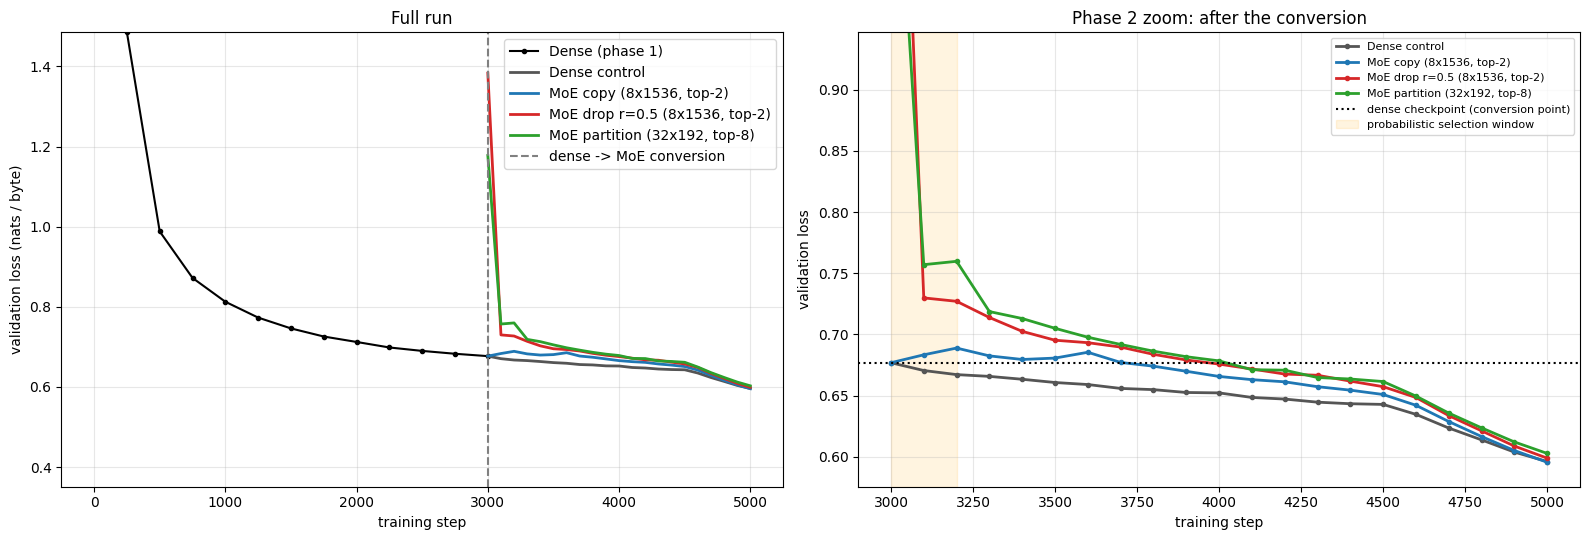

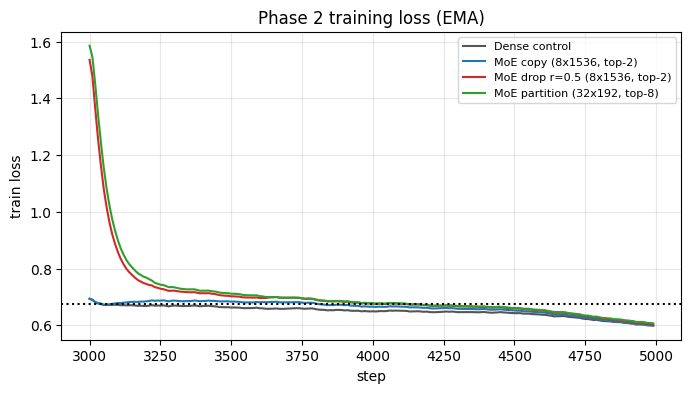

In [9]:
COLORS = {'Dense control': '#555555', 'MoE copy (8x1536, top-2)': '#1f77b4',
          'MoE drop r=0.5 (8x1536, top-2)': '#d62728', 'MoE partition (32x192, top-8)': '#2ca02c'}

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
ax = axes[0]
ax.plot(hist_dense['val_step'], hist_dense['val'], 'o-', color='black', ms=3, label='Dense (phase 1)')
for name, H in results.items():
    ax.plot(H['val_step'], H['val'], '-', color=COLORS[name], lw=2, label=name)
ax.axvline(DENSE_STEPS, ls='--', color='gray', label='dense -> MoE conversion')
ax.set_xlabel('training step'); ax.set_ylabel('validation loss (nats / byte)'); ax.set_title('Full run')
ax.set_ylim(top=min(ax.get_ylim()[1], hist_dense['val'][1] if len(hist_dense['val']) > 1 else ax.get_ylim()[1]))
ax.legend(); ax.grid(alpha=.3)

ax = axes[1]
for name, H in results.items():
    ax.plot(H['val_step'], H['val'], 'o-', ms=3, color=COLORS[name], lw=2, label=name)
ax.axhline(DENSE_CKPT_VAL, ls=':', color='black', label='dense checkpoint (conversion point)')
if EXPLORE:
    ax.axvspan(DENSE_STEPS, DENSE_STEPS + EXPLORE, color='orange', alpha=.12, label='probabilistic selection window')
ax.set_xlabel('training step'); ax.set_ylabel('validation loss'); ax.set_title('Phase 2 zoom: after the conversion')
allv = [v for H in results.values() for v in H['val']]
ax.set_ylim(min(allv) - 0.02, min(max(allv), DENSE_CKPT_VAL + 0.25) + 0.02)
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 4))
for name, H in results.items():
    plt.plot(H['tr_step'], H['tr'], color=COLORS[name], label=name)
plt.axhline(DENSE_CKPT_VAL, ls=':', color='black')
plt.title('Phase 2 training loss (EMA)'); plt.xlabel('step'); plt.ylabel('train loss'); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.show()

In [10]:
print(f"{'model':34s} {'total':>8s} {'active':>8s} {'val@convert':>12s} {'val final':>10s} {'drop vs ckpt':>13s} {'ms/step':>8s}")
print('-' * 100)
print(f"{'Dense checkpoint (phase 1 end)':34s} {fmt(param_counts(dense)[0]):>8s} {fmt(param_counts(dense)[1]):>8s} {'':>12s} {DENSE_CKPT_VAL:10.4f}")
for name, H in results.items():
    tot, act = param_counts(final_models[name])
    print(f"{name:34s} {fmt(tot):>8s} {fmt(act):>8s} {H['val'][0]:12.4f} {H['val'][-1]:10.4f} "
          f"{H['val'][-1]-DENSE_CKPT_VAL:+13.4f} {H['sec_per_step']*1000:8.0f}")

print('\nChecks:')
for name, H in results.items():
    v = H['val']
    mono = sum(b <= a + 1e-3 for a, b in zip(v, v[1:])) / max(1, len(v) - 1)
    print(f"  {name:34s} final < start: {v[-1] < v[0]} | final < dense ckpt: {v[-1] < DENSE_CKPT_VAL} | "
          f"evals that did not go up: {mono:.0%}")

model                                 total   active  val@convert  val final  drop vs ckpt  ms/step
----------------------------------------------------------------------------------------------------
Dense checkpoint (phase 1 end)       14.36M   14.36M                  0.6769
Dense control                        14.36M   14.36M       0.6769     0.5961       -0.0807      165
MoE copy (8x1536, top-2)             88.69M   24.99M       0.6769     0.5955       -0.0813      325
MoE drop r=0.5 (8x1536, top-2)       88.69M   24.99M       1.3832     0.5989       -0.0780      325
MoE partition (32x192, top-8)        46.28M   14.43M       1.1777     0.6027       -0.0741      478

Checks:
  Dense control                      final < start: True | final < dense ckpt: True | evals that did not go up: 100%
  MoE copy (8x1536, top-2)           final < start: True | final < dense ckpt: True | evals that did not go up: 80%
  MoE drop r=0.5 (8x1536, top-2)     final < start: True | final < dense ckpt: T

## 8. Load balance (§10, §13)

MaxVio = (max load − mean load) / mean load, averaged over layers and measured over 50-step windows; *dead* = expert with zero tokens in the window.
The shaded region is the probabilistic-selection window.

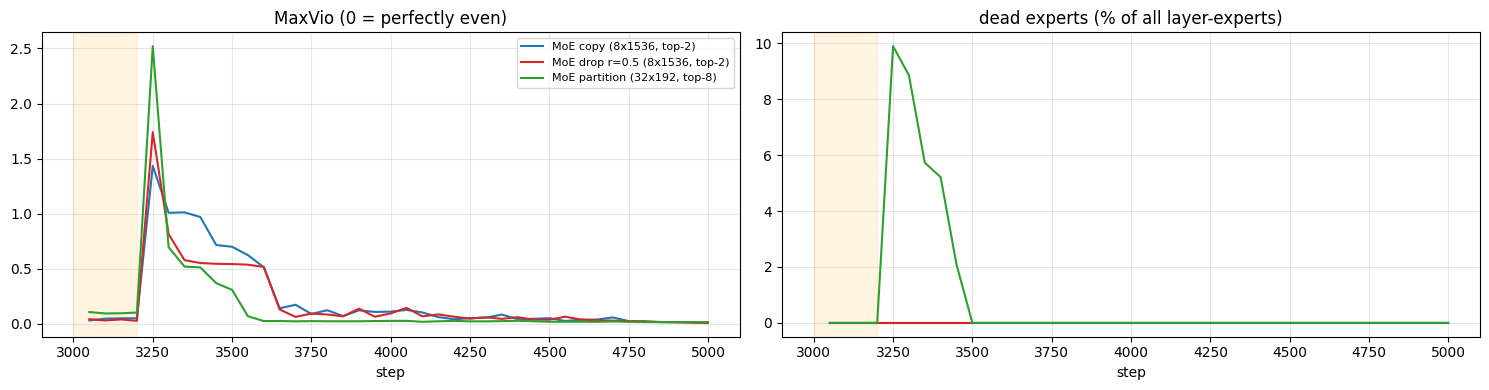

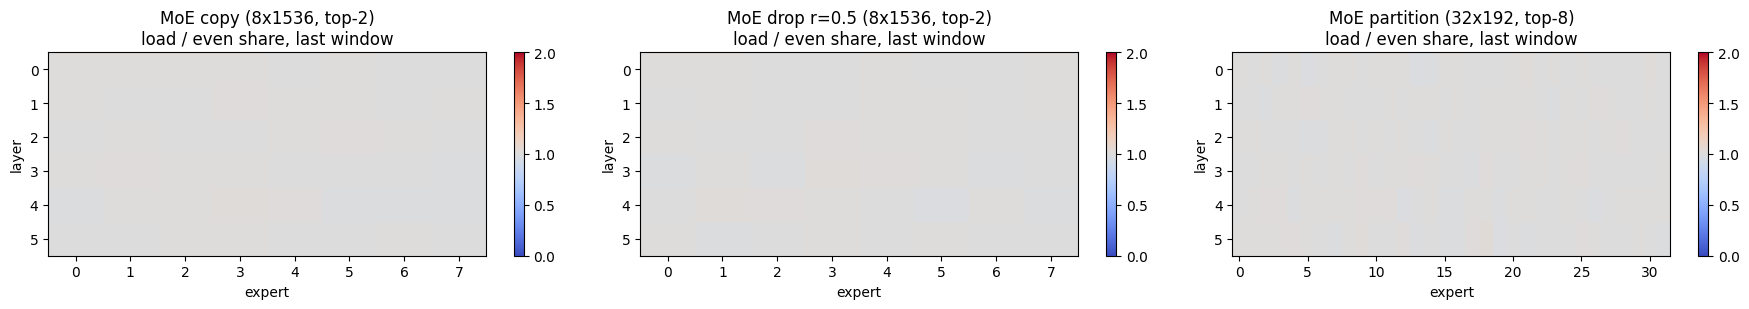

MoE copy (8x1536, top-2)           selection bias range: [-0.006, +0.116]
MoE drop r=0.5 (8x1536, top-2)     selection bias range: [-0.001, +0.128]
MoE partition (32x192, top-8)      selection bias range: [+0.030, +0.106]


In [11]:
moe_names = [n for n in results if n != 'Dense control']
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for n in moe_names:
    H = results[n]
    axes[0].plot(H['mv_step'], H['maxvio'], color=COLORS[n], label=n)
    L, E = len(final_models[n].moe_layers()), final_models[n].moe_layers()[0].E
    axes[1].plot(H['mv_step'], np.array(H['dead']) / (L * E) * 100, color=COLORS[n], label=n)
for a in axes:
    a.axvspan(DENSE_STEPS, DENSE_STEPS + EXPLORE, color='orange', alpha=.12); a.grid(alpha=.3); a.set_xlabel('step')
axes[0].set_title('MaxVio (0 = perfectly even)'); axes[1].set_title('dead experts (% of all layer-experts)')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(moe_names), figsize=(6 * len(moe_names), 3.2))
for a, n in zip(np.atleast_1d(axes), moe_names):
    load = results[n]['load']
    E = load.shape[1]
    im = a.imshow(load * E, aspect='auto', cmap='coolwarm', vmin=0, vmax=2)
    a.set_title(f'{n}\nload / even share, last window'); a.set_xlabel('expert'); a.set_ylabel('layer')
    plt.colorbar(im, ax=a)
plt.tight_layout(); plt.show()

for n in moe_names:
    b = torch.stack([m.sel_bias for m in final_models[n].moe_layers()]).cpu()
    print(f'{n:34s} selection bias range: [{b.min():+.3f}, {b.max():+.3f}]')

## 9. What did the experts learn? (§9)

For each byte class, the share of its routing assignments that goes to each expert (rows sum to 1).
If the lesson is right, the router groups tokens by **kind** (space, punctuation, capital letter, vowel …), strongest in some layers. Grey dashed line in the text below = uniform share.

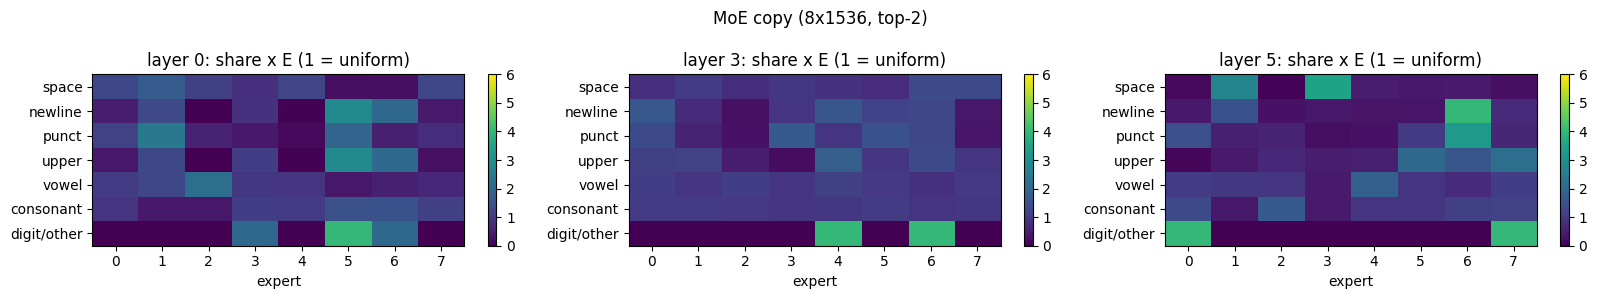

MoE copy (8x1536, top-2) | mean peak over-representation per layer: 2.5x 2.5x 2.0x 1.8x 1.9x 2.9x


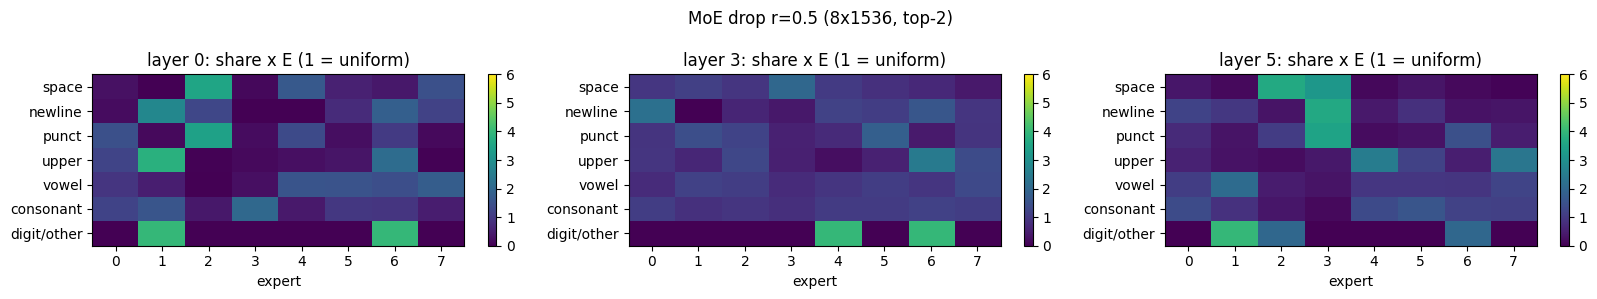

MoE drop r=0.5 (8x1536, top-2) | mean peak over-representation per layer: 3.1x 2.8x 2.2x 2.1x 2.1x 3.0x


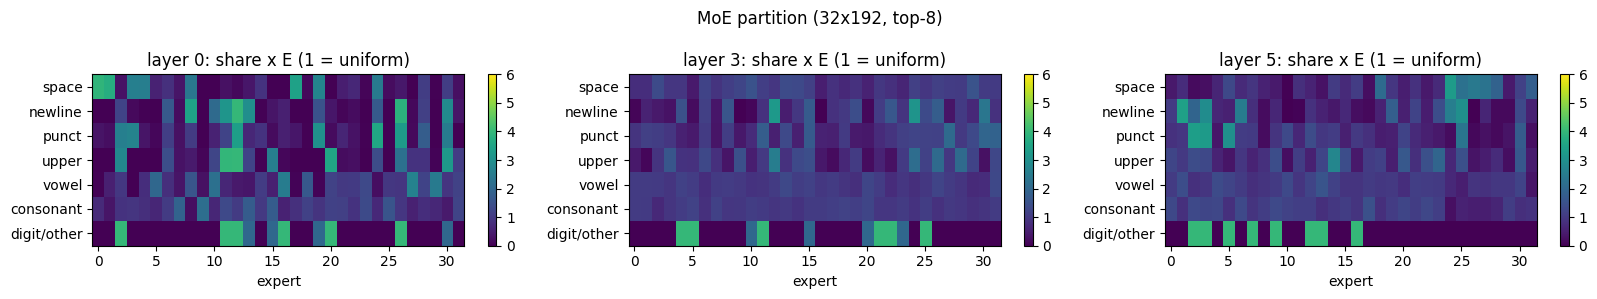

MoE partition (32x192, top-8) | mean peak over-representation per layer: 3.5x 2.7x 2.6x 2.3x 2.5x 2.8x


In [12]:
CLASSES = ['space', 'newline', 'punct', 'upper', 'vowel', 'consonant', 'digit/other']
def byte_class(b):
    c = chr(b) if b < 128 else ''
    if c == ' ': return 0
    if c == '\n': return 1
    if c and c in '.,!?;:\'"-()': return 2
    if c.isupper(): return 3
    if c in 'aeiou': return 4
    if c.isalpha(): return 5
    return 6
CLASS_OF = torch.tensor([byte_class(b) for b in range(256)])

@torch.no_grad()
def routing_by_class(model, n_batches=5):
    moes = model.moe_layers(); model.eval()
    for m in moes: m.record = True
    L, E = len(moes), moes[0].E
    M = torch.zeros(L, len(CLASSES), E)
    for x, y in VAL_BATCHES[:n_batches]:
        with torch.autocast(device_type=device, dtype=amp_dtype, enabled=use_amp):
            model(x)
        cls = CLASS_OF[x.cpu()]                                   # (B,T)
        for l, m in enumerate(moes):
            ti = m.last_topi.cpu()                                # (B,T,k)
            c = cls.unsqueeze(-1).expand_as(ti).reshape(-1)
            M[l].index_put_((c, ti.reshape(-1)), torch.ones(c.numel()), accumulate=True)
    for m in moes: m.record = False
    return M / M.sum(-1, keepdim=True).clamp_min(1)

for n in moe_names:
    M = routing_by_class(final_models[n])
    L, _, E = M.shape
    show = sorted(set([0, L // 2, L - 1]))
    fig, axes = plt.subplots(1, len(show), figsize=(5.5 * len(show), 3))
    for a, l in zip(np.atleast_1d(axes), show):
        im = a.imshow(M[l] * E, aspect='auto', cmap='viridis', vmin=0, vmax=min(6, E))
        a.set_yticks(range(len(CLASSES))); a.set_yticklabels(CLASSES); a.set_xlabel('expert')
        a.set_title(f'layer {l}: share x E (1 = uniform)')
        plt.colorbar(im, ax=a)
    fig.suptitle(n); plt.tight_layout(); plt.show()
    spec = (M * E).amax(-1).mean(-1)                               # avg over classes of the top expert's over-share
    print(n, '| mean peak over-representation per layer:', ' '.join(f'{s:.1f}x' for s in spec.tolist()))

## 10. Samples

In [13]:
@torch.no_grad()
def generate(model, prompt='Once upon a time', n=300, temperature=0.8, top_k=40):
    model.eval()
    idx = torch.tensor([list(prompt.encode('utf-8'))], device=device)
    for _ in range(n):
        with torch.autocast(device_type=device, dtype=amp_dtype, enabled=use_amp):
            logits, _ = model(idx[:, -model.cfg.block_size:])
        logits = logits[:, -1, :].float() / temperature
        v, _ = torch.topk(logits, top_k)
        logits[logits < v[:, [-1]]] = -float('inf')
        idx = torch.cat([idx, torch.multinomial(F.softmax(logits, -1), 1)], 1)
    return bytes(idx[0].tolist()).decode('utf-8', errors='replace')

torch.manual_seed(0)
for name, m in final_models.items():
    print(f'=== {name} ===')
    print(generate(m)); print()

=== Dense control ===
Once upon a time, there was a little girl named Lily. She loved to eat candy at school every day. One day, her mom told her to be careful and do her to send her to the airport. Lily didn't like to lie down at all, but her mom said they could buy her a sour soup for her.

Lily went to her mom and said she could pick

=== MoE copy (8x1536, top-2) ===
Once upon a time, there was a cat named Wooly. Wooly was very brave and had a nightmare in her house. She would often fight in her interesting wool.

Sometimes there was many books and toys and bugs. One day, when Cooly was building her own into the kitchen, she heard a sound. It was a surprise with a little girl w

=== MoE drop r=0.5 (8x1536, top-2) ===
Once upon a time there was a little girl named Daisy. Daisy loved to play outside and inch could share her food.

One day Daisy's friend, Susy, asked her why she looked down to take a closer look. Daisy told her "How could I polish Daisy?" Susy nodded and started to pol

## 11. Takeaways (from this run: Tesla T4, 3,000 dense steps + 2,000 continuation steps)

| model | total params | active params | val loss right after conversion | final val loss | change vs dense checkpoint (0.6769) |
|---|---|---|---|---|---|
| Dense control (keeps training) | 14.36M | 14.36M | 0.6769 | 0.5961 | −0.0807 |
| MoE copy (8 × 1536, top-2) | 88.69M | 24.99M | **0.6769** | **0.5955** | −0.0813 |
| MoE drop r = 0.5 (8 × 1536, top-2) | 88.69M | 24.99M | 1.3832 | 0.5989 | −0.0780 |
| MoE partition (32 × 192, top-8) | 46.28M | 14.43M | 1.1777 | 0.6027 | −0.0741 |

1. **The dense model was converted into an MoE, and it continued to train and reduce the loss.** All three MoE variants finished below the dense checkpoint they were grown from (0.6769 → 0.5955 / 0.5989 / 0.6027), and every expert in every layer was still receiving tokens at the end (0 dead experts).
2. **Copy-upcycling is function-preserving.** Its validation loss right after conversion was 0.6769, identical to the dense model, because all experts equal the dense FFN and the top-k weights sum to 1.
3. **Drop and partition pay an upfront cost and recover quickly.** Redrawing half of each expert's neurons (drop) raised the loss to 1.38, and re-assembling the FFN from random 192-wide slices (partition) raised it to 1.18. Both were back to ~0.73–0.76 within 100 steps and kept falling for the rest of training.
4. **The probabilistic-selection window had a cost for the copy arm.** During the first 200 steps (Gumbel top-k), copy's loss rose slightly (0.6769 → 0.6888) before falling steadily from step ~3,600. The switch from probabilistic to hard top-k at step 3,200 also produced a MaxVio spike (up to ~2.5) and, for partition, briefly left ~10 % of experts without tokens. Dead experts were back to 0 within ~300 steps, and the bias balancing brought MaxVio down to ≤ 0.02 by the end of training.
5. **At this budget the MoE did not beat the dense control.** Copy tied it (0.5955 vs 0.5961); drop and partition finished 0.003 and 0.007 behind. Copy and drop use ~2× the dense FFN compute per token, so a tie is not a win for them. The compute-matched partition arm (8 × 192 = 1,536 active width, like the lesson's 8 × 768 = 6,144) was still recovering from its conversion cost. Plausible reasons (not tested here): a small 14M-parameter base model on an easy dataset, a short 2,000-step continuation, and the exploration window above. Lowering or removing exploration for the copy arm and training longer are the first things to try.
6. **Experts specialized by kind of token, as §9 describes.** In the first and last layers, individual experts receive spaces, newlines, punctuation or digits at 3–4× their even share, while vowels and consonants are spread fairly evenly. Middle layers are the least specialized (mean peak over-representation ~1.8–2.6× in layers 2–4 vs ~2.5–3.5× in layers 0 and 5).
7. **All four models generate coherent TinyStories-style text** (section 10).

**Things to try next:** `explore_steps=0` for the copy arm; longer continuation (e.g. 6,000 steps); `bias_gamma=0, aux_coef=0` to watch routing collapse; `drop_ratio` in {0.25, 0.75}; more experts at the same top-k.
